In [1]:
import numpy as np
import pandas as pd
import os
import glob

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, accuracy_score

import warnings
warnings.filterwarnings('ignore')

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [2]:
import os
import glob
import pandas as pd

print("Available Kaggle Datasets:")

for path in glob.glob("/kaggle/input/*"):
    print(path)

Available Kaggle Datasets:
/kaggle/input/competitions


In [3]:
files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

for file in files:
    print(file)

/kaggle/input/competitions/llm-classification-finetuning/sample_submission.csv
/kaggle/input/competitions/llm-classification-finetuning/train.csv
/kaggle/input/competitions/llm-classification-finetuning/test.csv


In [4]:
import glob
import os
import pandas as pd

files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

train_path = [f for f in files if 'train.csv' in f][0]
test_path = [f for f in files if 'test.csv' in f][0]
sample_path = [f for f in files if 'sample_submission.csv' in f][0]

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)
sample = pd.read_csv(sample_path)

print("Dataset Loaded Successfully!")
print("Train:", train.shape)
print("Test:", test.shape)

train.head()

Dataset Loaded Successfully!
Train: (57477, 9)
Test: (3, 4)


,id,model_a,model_b,prompt,response_a,response_b,winner_model_a,winner_model_b,winner_tie
0,30192,gpt-4-1106-preview,gpt-4-0613,"[""Is it morally right to try to have a certain...","[""The question of whether it is morally right ...","[""As an AI, I don't have personal beliefs or o...",1,0,0
1,53567,koala-13b,gpt-4-0613,"[""What is the difference between marriage lice...","[""A marriage license is a legal document that ...","[""A marriage license and a marriage certificat...",0,1,0
2,65089,gpt-3.5-turbo-0613,mistral-medium,"[""explain function calling. how would you call...","[""Function calling is the process of invoking ...","[""Function calling is the process of invoking ...",0,0,1
3,96401,llama-2-13b-chat,mistral-7b-instruct,"[""How can I create a test set for a very rare ...","[""Creating a test set for a very rare category...","[""When building a classifier for a very rare c...",1,0,0
4,198779,koala-13b,gpt-3.5-turbo-0314,"[""What is the best way to travel from Tel-Aviv...","[""The best way to travel from Tel Aviv to Jeru...","[""The best way to travel from Tel-Aviv to Jeru...",0,1,0


Columns:
['id', 'model_a', 'model_b', 'prompt', 'response_a', 'response_b', 'winner_model_a', 'winner_model_b', 'winner_tie']

Missing Values:
id                0
model_a           0
model_b           0
prompt            0
response_a        0
response_b        0
winner_model_a    0
winner_model_b    0
winner_tie        0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57477 entries, 0 to 57476
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id              57477 non-null  int64 
 1   model_a         57477 non-null  object
 2   model_b         57477 non-null  object
 3   prompt          57477 non-null  object
 4   response_a      57477 non-null  object
 5   response_b      57477 non-null  object
 6   winner_model_a  57477 non-null  int64 
 7   winner_model_b  57477 non-null  int64 
 8   winner_tie      57477 non-null  int64 
dtypes: int64(4), object(5)
memory usage: 3.9+ MB


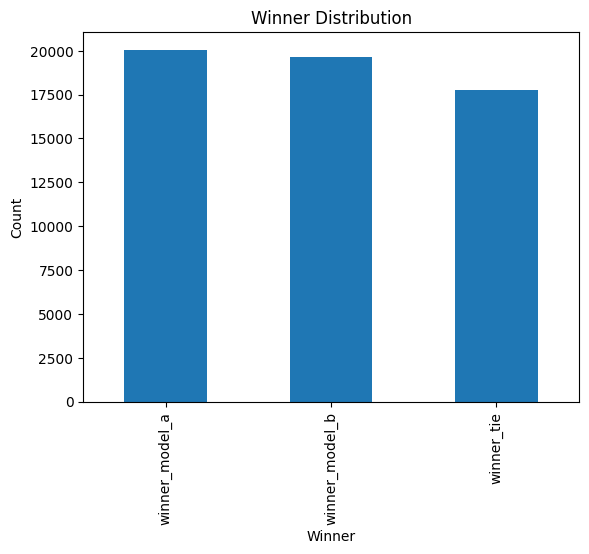

In [5]:
print("Columns:")
print(train.columns.tolist())

print("\nMissing Values:")
print(train.isnull().sum())

print("\nDataset Information:")
train.info()

import matplotlib.pyplot as plt

target_cols = [
    'winner_model_a',
    'winner_model_b',
    'winner_tie'
]

train[target_cols].sum().plot(kind='bar')

plt.title("Winner Distribution")
plt.xlabel("Winner")
plt.ylabel("Count")
plt.show()

In [6]:
def prepare_text(df):

    prompt = df['prompt'].fillna('').astype(str)
    response_a = df['response_a'].fillna('').astype(str)
    response_b = df['response_b'].fillna('').astype(str)

    return (
        "Prompt: " + prompt +
        " Response A: " + response_a +
        " Response B: " + response_b
    )

X = prepare_text(train)
X_test = prepare_text(test)

y = train[target_cols].values.argmax(axis=1)

print("Preprocessing Done!")

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", len(X_train))
print("Validation:", len(X_val))

from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=100000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
    dtype='float32'
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)

print("Vectorization Completed!")

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    C=4,
    max_iter=200,
    solver='saga',
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Model Training Completed!")

from sklearn.metrics import accuracy_score, log_loss

pred = model.predict(X_val_tfidf)
prob = model.predict_proba(X_val_tfidf)

print("Accuracy:", accuracy_score(y_val, pred))

print("Log Loss:", log_loss(
    y_val,
    prob,
    labels=[0, 1, 2]
))

Preprocessing Done!
Training: 45981
Validation: 11496
Vectorization Completed!
Model Training Completed!
Accuracy: 0.3783054975643702
Log Loss: 1.202871790311019


In [7]:
final_vectorizer = TfidfVectorizer(
    max_features=100000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
    dtype='float32'
)

X_full = final_vectorizer.fit_transform(X)
X_test_tfidf = final_vectorizer.transform(X_test)

final_model = LogisticRegression(
    C=4,
    max_iter=200,
    solver='saga',
    random_state=42
)

final_model.fit(X_full, y)

print("Final Training Completed!")

predictions = final_model.predict_proba(X_test_tfidf)

print(predictions[:5])

submission = pd.DataFrame({
    'id': test['id'],
    'winner_model_a': predictions[:, 0],
    'winner_model_b': predictions[:, 1],
    'winner_tie': predictions[:, 2]
})

submission.to_csv('submission.csv', index=False)

print("Submission Created!")
submission.head()

Final Training Completed!
[[0.15296255 0.45731193 0.3897255 ]
 [0.65087944 0.10020877 0.24891177]
 [0.1563349  0.77777493 0.06589022]]
Submission Created!


,id,winner_model_a,winner_model_b,winner_tie
0,136060,0.152963,0.457312,0.389726
1,211333,0.650879,0.100209,0.248912
2,1233961,0.156335,0.777775,0.065890


In [8]:
check = pd.read_csv('submission.csv')

print(check.head())
print("Shape:", check.shape)

print("Probability Sum:")
print(check[target_cols].sum(axis=1).head())

print("Missing Values:")
print(check.isnull().sum())

        id  winner_model_a  winner_model_b  winner_tie
0   136060        0.152963        0.457312    0.389726
1   211333        0.650879        0.100209    0.248912
2  1233961        0.156335        0.777775    0.065890
Shape: (3, 4)
Probability Sum:
0    1.0
1    1.0
2    1.0
dtype: float64
Missing Values:
id                0
winner_model_a    0
winner_model_b    0
winner_tie        0
dtype: int64
